In [ ]:

!pip install opencv-python matplotlib numpy


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("All libraries imported successfully!")


OpenCV version: 5.0.0
All libraries imported successfully!


In [ ]:

from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

image_name = next(iter(uploaded))

image = cv2.imdecode(
    np.frombuffer(uploaded[image_name], np.uint8),
    cv2.IMREAD_COLOR
)

if image is None:
    raise ValueError("Could not load the image.")

print("Uploaded image:", image_name)
print("Image dimensions:", image.shape)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Road Image")
plt.axis("off")
plt.show()


Saving archive (2).zip to archive (2).zip


ValueError: Could not load the image.

In [ ]:

import zipfile
import os

zip_path = "/content/archive (2).zip"
extract_path = "/content/pothole_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("\nFiles and folders:")

for root, dirs, files_list in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for filename in files_list[:10]:
        print(f"{indent}  {filename}")

    dirs[:] = dirs[:10]

    if level >= 2:
        dirs[:] = []


Dataset extracted successfully!

Files and folders:
pothole_dataset/
  splits.json
  README.md
  annotated-images/
    img-194.xml
    img-478.jpg
    img-528.xml
    img-238.xml
    img-282.xml
    img-118.xml
    img-471.jpg
    img-535.jpg
    img-540.xml
    img-211.jpg


In [ ]:

import os

dataset_path = "/content/pothole_dataset/annotated-images"

image_files = [
    f for f in os.listdir(dataset_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

xml_files = [
    f for f in os.listdir(dataset_path)
    if f.lower().endswith(".xml")
]

print("Total road images:", len(image_files))
print("Total annotation files:", len(xml_files))

print("\nSample road images:")
print(image_files[:10])

print("\nSample annotation files:")
print(xml_files[:10])


Total road images: 665
Total annotation files: 665

Sample road images:
['img-478.jpg', 'img-471.jpg', 'img-535.jpg', 'img-211.jpg', 'img-564.jpg', 'img-424.jpg', 'img-594.jpg', 'img-365.jpg', 'img-506.jpg', 'img-461.jpg']

Sample annotation files:
['img-194.xml', 'img-528.xml', 'img-238.xml', 'img-282.xml', 'img-118.xml', 'img-540.xml', 'img-558.xml', 'img-134.xml', 'img-141.xml', 'img-289.xml']


Image name: img-1.jpg
Image dimensions: (720, 720, 3)


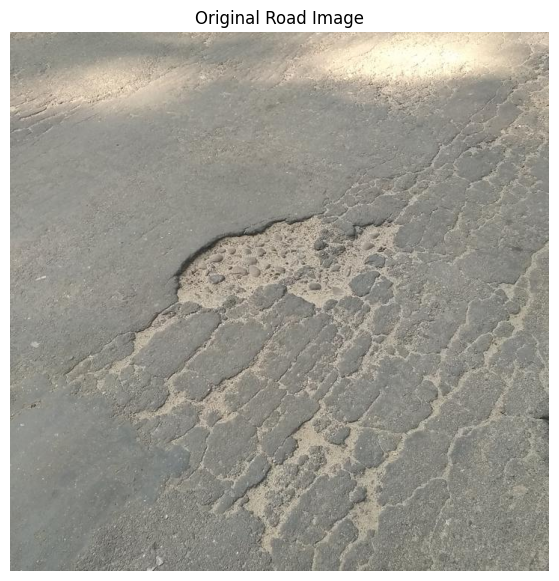

In [ ]:

import os
import cv2
import matplotlib.pyplot as plt

dataset_path = "/content/pothole_dataset/annotated-images"

# Find an available road image
image_files = sorted([
    f for f in os.listdir(dataset_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Load the first image
image_name = image_files[0]
image_path = os.path.join(dataset_path, image_name)

image = cv2.imread(image_path)

if image is None:
    raise ValueError(f"Could not load image: {image_path}")

# Convert BGR to RGB for display
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image name:", image_name)
print("Image dimensions:", image.shape)

plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
plt.title("Original Road Image")
plt.axis("off")
plt.show()


In [ ]:

import os
import xml.etree.ElementTree as ET

dataset_path = "/content/pothole_dataset/annotated-images"

image_name = "img-1.jpg"
xml_name = os.path.splitext(image_name)[0] + ".xml"
xml_path = os.path.join(dataset_path, xml_name)

if not os.path.exists(xml_path):
    print("Annotation not found:", xml_name)
    print("We will check the available XML filenames next.")
else:
    tree = ET.parse(xml_path)
    root = tree.getroot()

    print("Annotation file:", xml_name)
    print("\nImage information:")

    size = root.find("size")
    if size is not None:
        for item in size:
            print(item.tag, ":", item.text)

    print("\nDetected objects:")
    objects = root.findall("object")

    for i, obj in enumerate(objects, start=1):
        name = obj.findtext("name", default="unknown")
        box = obj.find("bndbox")

        print(f"\nObject {i}: {name}")

        if box is not None:
            for key in ["xmin", "ymin", "xmax", "ymax"]:
                print(f"{key}: {box.findtext(key)}")

    if not objects:
        print("No annotated objects found in this XML file.")


Annotation file: img-1.xml

Image information:
width : 720
height : 720
depth : 3

Detected objects:

Object 1: pothole
xmin: 213
ymin: 240
xmax: 525
ymax: 378


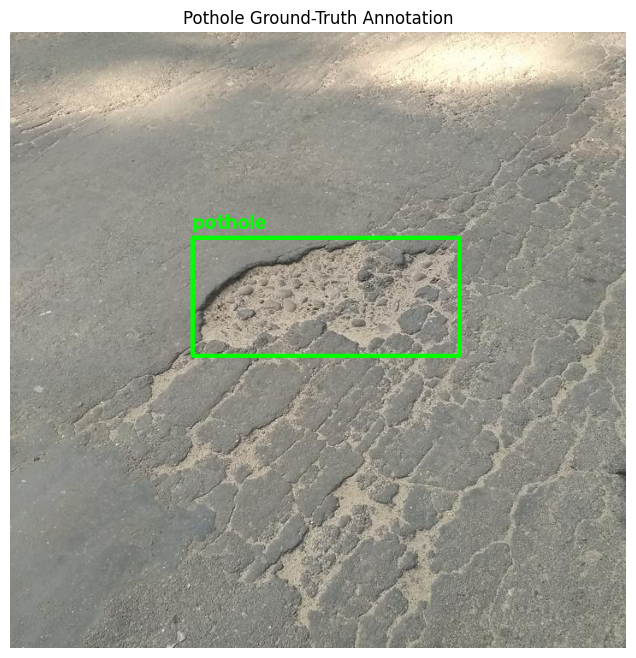

Bounding box drawn successfully!


In [ ]:

import cv2
import os
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

dataset_path = "/content/pothole_dataset/annotated-images"

image_name = "img-1.jpg"
image_path = os.path.join(dataset_path, image_name)
xml_path = os.path.join(
    dataset_path,
    os.path.splitext(image_name)[0] + ".xml"
)

# Load the road image
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Image could not be loaded.")

# Read the XML annotation
root = ET.parse(xml_path).getroot()

# Draw each annotated pothole
for obj in root.findall("object"):
    label = obj.findtext("name", default="pothole")
    box = obj.find("bndbox")

    if box is None:
        continue

    xmin = int(box.findtext("xmin"))
    ymin = int(box.findtext("ymin"))
    xmax = int(box.findtext("xmax"))
    ymax = int(box.findtext("ymax"))

    cv2.rectangle(
        image,
        (xmin, ymin),
        (xmax, ymax),
        (0, 255, 0),
        3
    )

    cv2.putText(
        image,
        label,
        (xmin, max(ymin - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

# Display the annotated image
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.title("Pothole Ground-Truth Annotation")
plt.axis("off")
plt.show()

print("Bounding box drawn successfully!")


In [ ]:

import os
import random
import shutil
import xml.etree.ElementTree as ET
import cv2

# Original dataset
source_dir = "/content/pothole_dataset/annotated-images"

# New YOLO dataset
output_dir = "/content/pothole_yolo"

# Find images that have matching XML annotations
image_files = []

for filename in os.listdir(source_dir):
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
        image_path = os.path.join(source_dir, filename)
        xml_path = os.path.join(
            source_dir, os.path.splitext(filename)[0] + ".xml"
        )

        if os.path.exists(xml_path):
            image_files.append(filename)

random.seed(42)
random.shuffle(image_files)

# Split into training, validation, and testing sets
n = len(image_files)
train_end = int(n * 0.8)
val_end = int(n * 0.9)

splits = {
    "train": image_files[:train_end],
    "val": image_files[train_end:val_end],
    "test": image_files[val_end:]
}

# Create folders
for split in splits:
    os.makedirs(f"{output_dir}/images/{split}", exist_ok=True)
    os.makedirs(f"{output_dir}/labels/{split}", exist_ok=True)

converted = 0
skipped = 0

for split, filenames in splits.items():
    for filename in filenames:
        image_path = os.path.join(source_dir, filename)
        xml_path = os.path.join(
            source_dir, os.path.splitext(filename)[0] + ".xml"
        )

        image = cv2.imread(image_path)
        if image is None:
            skipped += 1
            continue

        height, width = image.shape[:2]
        root = ET.parse(xml_path).getroot()
        label_lines = []

        for obj in root.findall("object"):
            name = obj.findtext("name", default="").strip().lower()

            # Our project has one class: pothole
            if name != "pothole":
                continue

            box = obj.find("bndbox")
            if box is None:
                continue

            xmin = float(box.findtext("xmin"))
            ymin = float(box.findtext("ymin"))
            xmax = float(box.findtext("xmax"))
            ymax = float(box.findtext("ymax"))

            # Check bounding-box coordinates
            xmin = max(0, min(xmin, width))
            xmax = max(0, min(xmax, width))
            ymin = max(0, min(ymin, height))
            ymax = max(0, min(ymax, height))

            if xmax <= xmin or ymax <= ymin:
                continue

            # Convert to YOLO format:
            # class_id, center_x, center_y, box_width, box_height
            center_x = ((xmin + xmax) / 2) / width
            center_y = ((ymin + ymax) / 2) / height
            box_width = (xmax - xmin) / width
            box_height = (ymax - ymin) / height

            label_lines.append(
                f"0 {center_x:.6f} {center_y:.6f} "
                f"{box_width:.6f} {box_height:.6f}"
            )

        # Copy image and write YOLO label file
        shutil.copy2(
            image_path,
            f"{output_dir}/images/{split}/{filename}"
        )

        label_name = os.path.splitext(filename)[0] + ".txt"
        label_path = f"{output_dir}/labels/{split}/{label_name}"

        with open(label_path, "w") as f:
            f.write("\n".join(label_lines))

        converted += 1

# Create YOLO configuration file
yaml_path = f"{output_dir}/data.yaml"

with open(yaml_path, "w") as f:
    f.write(f"path: {output_dir}\n")
    f.write("train: images/train\n")
    f.write("val: images/val\n")
    f.write("test: images/test\n")
    f.write("names:\n")
    f.write("  0: pothole\n")

print("YOLO dataset preparation complete!")
print("Images processed:", converted)
print("Images skipped:", skipped)
print("Training images:", len(splits["train"]))
print("Validation images:", len(splits["val"]))
print("Testing images:", len(splits["test"]))
print("Configuration:", yaml_path)


YOLO dataset preparation complete!
Images processed: 665
Images skipped: 0
Training images: 532
Validation images: 66
Testing images: 67
Configuration: /content/pothole_yolo/data.yaml


In [ ]:

!pip install -q ultralytics

from ultralytics import YOLO
import torch

print("GPU available:", torch.cuda.is_available())

# Load a pretrained lightweight YOLOv8 model
model = YOLO("yolov8n.pt")

# Train using your prepared pothole dataset
results = model.train(
    data="/content/pothole_yolo/data.yaml",
    epochs=30,
    imgsz=640,
    batch=8,
    patience=10,
    project="/content/pothole_runs",
    name="pothole_yolov8n",
    plots=True
)

print("Training finished!")
print("Best model location:")
print("/content/pothole_runs/pothole_yolov8n/weights/best.pt")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU available: False
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pothole_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torc

In [ ]:

from ultralytics import YOLO

# Load the best trained model
model = YOLO(
    "/content/pothole_runs/pothole_yolov8n/weights/best.pt"
)

# Evaluate on the separate test dataset
test_results = model.val(
    data="/content/pothole_yolo/data.yaml",
    split="test",
    imgsz=640,
    batch=8,
    plots=True,
    project="/content/pothole_runs",
    name="pothole_test_results"
)

print("\nTEST SET RESULTS")
print("Precision:", round(test_results.box.mp, 4))
print("Recall:", round(test_results.box.mr, 4))
print("mAP@50:", round(test_results.box.map50, 4))
print("mAP@50-95:", round(test_results.box.map, 4))


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 26.9±24.9 MB/s, size: 89.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/pothole_yolo/labels/test... 67 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67 277.1it/s 0.2s
val: New cache created: /content/pothole_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.6s/it 23.1s
                   all         67        193      0.806      0.653      0.776      0.479
Speed: 3.8ms preprocess, 323.2ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /content/pothole_runs/pothole_test_results

TEST SET RESULTS
Precision: 0.8057
Recall: 0.652

Testing image: img-594.jpg

image 1/1 /content/pothole_yolo/images/test/img-594.jpg: 448x640 5 potholes, 482.7ms
Speed: 4.5ms preprocess, 482.7ms inference, 3.9ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/pothole_runs/pothole_prediction


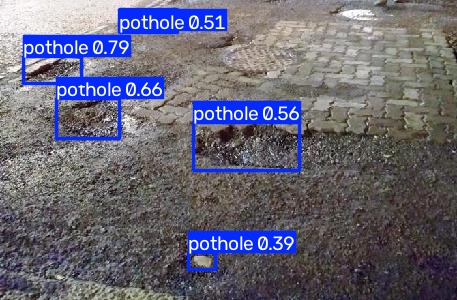

In [ ]:

from ultralytics import YOLO
from IPython.display import display, Image
import glob
import os

# Load your trained model
model = YOLO(
    "/content/pothole_runs/pothole_yolov8n/weights/best.pt"
)

# Select one image from the test dataset
test_images = glob.glob(
    "/content/pothole_yolo/images/test/*.jpg"
)

image_path = test_images[0]
print("Testing image:", os.path.basename(image_path))

# Detect potholes and save the result
model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25,
    save=True,
    project="/content/pothole_runs",
    name="pothole_prediction"
)

# Display the image with predicted bounding boxes
result_image = glob.glob(
    "/content/pothole_runs/pothole_prediction/*.jpg"
)[0]

display(Image(filename=result_image, width=600))


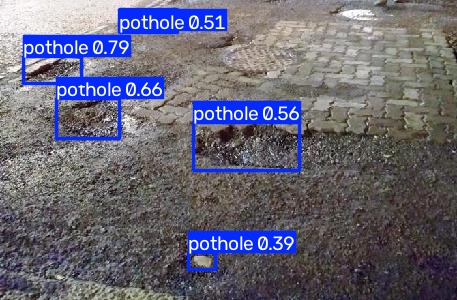

In [ ]:

from IPython.display import display, Image

result_image = (
    "/content/pothole_runs/pothole_prediction/img-594.jpg"
)

display(Image(filename=result_image, width=700))


In [ ]:

import os
import shutil

# Create a folder for the final model
os.makedirs("/content/Pothole_Detection_Project", exist_ok=True)

# Copy the best trained model into the project folder
shutil.copy(
    "/content/pothole_runs/pothole_yolov8n/weights/best.pt",
    "/content/Pothole_Detection_Project/best.pt"
)

print("Model saved successfully!")
print("Location: /content/Pothole_Detection_Project/best.pt")
print("File size:",
      round(os.path.getsize(
          "/content/Pothole_Detection_Project/best.pt"
      ) / (1024 * 1024), 2), "MB")


Model saved successfully!
Location: /content/Pothole_Detection_Project/best.pt
File size: 6.2 MB


In [ ]:

import os
import shutil

project = "/content/Pothole_Detection_Project"

# Create folders for results
os.makedirs(f"{project}/results", exist_ok=True)

# Copy the prediction image
shutil.copy(
    "/content/pothole_runs/pothole_prediction/img-594.jpg",
    f"{project}/results/pothole_detection_result.jpg"
)

# Create a test results report
report = """ROAD POTHOLE DETECTION USING COMPUTER VISION

Model: YOLOv8n
Dataset: Pothole detection dataset
Training images: 532
Validation images: 66
Test images: 67
Test pothole instances: 193

FINAL TEST RESULTS
Precision: 80.57%
Recall: 65.28%
mAP@50: 77.60%
mAP@50-95: 47.94%

Sample prediction:
The model detected 5 potholes in img-594.jpg.

Note:
Performance is measured on the held-out test dataset.
Results may vary with lighting, road conditions, and image quality.
"""

with open(f"{project}/results/test_report.txt", "w") as f:
    f.write(report)

print("Project results saved successfully!")
print("Files in results folder:")
for file in os.listdir(f"{project}/results"):
    print("-", file)


Project results saved successfully!
Files in results folder:
- pothole_detection_result.jpg
- test_report.txt


In [ ]:

project = "/content/Pothole_Detection_Project"

readme = """# Road Pothole Detection Using Computer Vision

## 1. Project Overview
This project uses YOLOv8n, a deep-learning object detection model,
to identify potholes in road images and mark them with bounding boxes.

## 2. Objectives
- Detect potholes in road images.
- Draw bounding boxes around detected potholes.
- Evaluate the model using a separate test dataset.

## 3. Technologies Used
- Python
- Google Colab
- Ultralytics YOLOv8
- PyTorch
- OpenCV
- NumPy

## 4. Dataset
- Training images: 532
- Validation images: 66
- Test images: 67
- Test pothole instances: 193
- Object class: pothole

## 5. Model
YOLOv8n was trained for 30 epochs.

## 6. Test Results
- Precision: 80.57%
- Recall: 65.28%
- mAP@50: 77.60%
- mAP@50-95: 47.94%

These values are from evaluation on the held-out test split.

## 7. Sample Prediction
The sample image img-594.jpg produced 5 pothole detections.
See results/pothole_detection_result.jpg.

## 8. Project Files
- best.pt: trained model weights
- results/pothole_detection_result.jpg: sample detection output
- results/test_report.txt: test evaluation report
- README.md: project documentation

## 9. How to Use the Model
Install the Ultralytics package:

    pip install ultralytics

Example Python code:

    from ultralytics import YOLO

    model = YOLO("best.pt")
    model.predict(source="road_image.jpg", save=True, conf=0.25)

Replace road_image.jpg with the path to your own road image.

## 10. Limitations
Detection performance may vary with lighting, image quality,
camera angle, road conditions, and pothole appearance.
This project is a computer vision prototype and should not be
treated as a substitute for professional road inspection.

## 11. Conclusion
The project demonstrates how a YOLOv8 object detection model can
be trained and evaluated to identify potholes in road images.
"""

with open(f"{project}/README.md", "w") as f:
    f.write(readme)

print("README.md created successfully!")
print("Location:", f"{project}/README.md")


README.md created successfully!
Location: /content/Pothole_Detection_Project/README.md


In [ ]:

import os
import zipfile

project = "/content/Pothole_Detection_Project"
zip_path = "/content/Pothole_Detection_Project.zip"

# Create the ZIP file
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(project):
        for file in files:
            full_path = os.path.join(root, file)
            relative_path = os.path.relpath(full_path, project)
            zipf.write(full_path, relative_path)

print("ZIP file created successfully!")
print("ZIP location:", zip_path)
print("ZIP size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

print("\nProject files:")
for root, dirs, files in os.walk(project):
    for file in files:
        print("-", os.path.relpath(os.path.join(root, file), project))


ZIP file created successfully!
ZIP location: /content/Pothole_Detection_Project.zip
ZIP size: 5.71 MB

Project files:
- README.md
- best.pt
- results/pothole_detection_result.jpg
- results/test_report.txt


In [ ]:

from google.colab import files

files.download("/content/Pothole_Detection_Project.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PASS: Saved model loaded successfully.

image 1/1 /content/pothole_yolo/images/test/img-594.jpg: 448x640 5 potholes, 325.4ms
Speed: 12.6ms preprocess, 325.4ms inference, 1.1ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/Pothole_Detection_Project/verification
PASS: Prediction completed.
Potholes detected: 5
PASS: Prediction image saved.


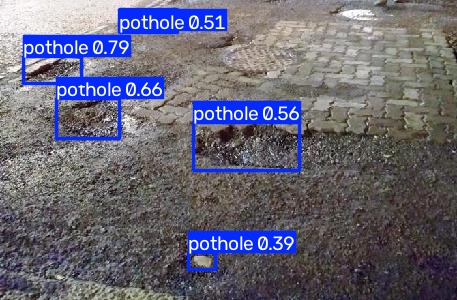

In [ ]:

from ultralytics import YOLO
from IPython.display import display, Image
import os

# 1. Check that the saved model exists
model_path = "/content/Pothole_Detection_Project/best.pt"

assert os.path.exists(model_path), "ERROR: Model file not found!"

# 2. Load the saved model
model = YOLO(model_path)
print("PASS: Saved model loaded successfully.")

# 3. Test it on a test image
image_path = "/content/pothole_yolo/images/test/img-594.jpg"

assert os.path.exists(image_path), "ERROR: Test image not found!"

results = model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25,
    save=True,
    project="/content/Pothole_Detection_Project",
    name="verification",
    exist_ok=True
)

# 4. Count detected potholes
pothole_count = sum(
    len(result.boxes) for result in results
)

print("PASS: Prediction completed.")
print("Potholes detected:", pothole_count)

# 5. Display the prediction
result_image = (
    "/content/Pothole_Detection_Project/"
    "verification/img-594.jpg"
)

if os.path.exists(result_image):
    print("PASS: Prediction image saved.")
    display(Image(filename=result_image, width=650))
else:
    print("WARNING: Prediction image was not found.")


In [ ]:

import zipfile
import os

zip_path = "/content/Pothole_Detection_Project.zip"

# Check that the ZIP file exists
if not os.path.exists(zip_path):
    print("ERROR: ZIP file not found. Create it again first.")
else:
    with zipfile.ZipFile(zip_path, "r") as zipf:
        print("ZIP integrity check:",
              "PASS" if zipf.testzip() is None else "FAIL")

        print("\nFiles inside the ZIP:")
        for name in zipf.namelist():
            print("PASS:", name)

        required_files = [
            "best.pt",
            "README.md",
            "results/pothole_detection_result.jpg",
            "results/test_report.txt"
        ]

        print("\nRequired file checks:")
        for name in required_files:
            status = "PASS" if name in zipf.namelist() else "MISSING"
            print(status + ":", name)


ZIP integrity check: PASS

Files inside the ZIP:
PASS: README.md
PASS: best.pt
PASS: results/pothole_detection_result.jpg
PASS: results/test_report.txt

Required file checks:
PASS: best.pt
PASS: README.md
PASS: results/pothole_detection_result.jpg
PASS: results/test_report.txt
